In [2]:
# divide study area into different precipitation zones using weighted k-means clustering
# Version for final run -  2026-10-27 - JPK
# V2 - 2026-10-27 -- implemented standard scaling before weight application

#current approach:
#1. use weights from rf permutation feature importance calculated based on 20 years average climatology
#2. first apply weighted k-means clustering
#3. determine n clusters using elbow + silhouette score
#4. improve spatial coherence (removing salt and pepper noise))



In [3]:
#Libraries

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import xarray as xr
import rioxarray as rxr
import os
import gc
from sklearn.preprocessing import StandardScaler
from sklearn import metrics
from scipy.spatial.distance import cdist

# paths
feature_importance = pd.read_csv(r"E:\ClimateData_Precipitation\Data\Processed\Spatial_clustering\climatology_weight_prec.csv")
clim_file_path = r"E:\ClimateData_Precipitation\Data\Processed\Spatial_clustering\Climatology_files"
file_list = [f for f in os.listdir(clim_file_path) if f.endswith(".tif")]
sample_raster = rxr.open_rasterio(r"E:\ClimateData_Precipitation\Data\Datasets\Sample_raster\DEM_1km_elevation_max.tif")

In [4]:
#1. prepare normalized and weighted raster for each variable rasters

weights = feature_importance.set_index('Unnamed: 0')['importance'].to_dict()

data_arrays = {}
for file in file_list:
    var_name = file.split(".")[0]
    da = rxr.open_rasterio(os.path.join(clim_file_path, file), masked=True)
    da = da.rio.reproject_match(sample_raster)
    
    if da.shape[0] == 1:
        da = da.squeeze('band', drop=True)
    
    data_arrays[var_name] = da

stacked_ds = xr.Dataset(data_arrays)

del data_arrays
gc.collect()

353

In [5]:
#convert to dataframe for easy handling
y_dim = stacked_ds.rio.y_dim  
x_dim = stacked_ds.rio.x_dim

valid_mask = None
for var in stacked_ds.data_vars:
    var_mask = ~np.isnan(stacked_ds[var].values)
    valid_mask = var_mask if valid_mask is None else valid_mask & var_mask

stacked_ds_dict = {}
for var in stacked_ds.data_vars:
    stacked_ds_dict[var] = stacked_ds[var].values[valid_mask].flatten().astype('float32')

stacked_df = pd.DataFrame(stacked_ds_dict, dtype='float32')
del stacked_ds_dict, var_mask
gc.collect()

# %%
# Store spatial info
spatial_coords = {
    'x': stacked_ds[x_dim].values,
    'y': stacked_ds[y_dim].values,
    'crs': stacked_ds.rio.crs,
    'transform': stacked_ds.rio.transform(),
    'shape': (len(stacked_ds[y_dim]), len(stacked_ds[x_dim]))
}

del stacked_ds
gc.collect()

431

In [6]:
# Separate features and target, standardize, then apply weights
target_col = 'prec_climatology'
feature_cols = [c for c in stacked_df.columns if c != target_col]
all_cols = feature_cols + [target_col]

# 1. Z-score every column so units/ranges no longer decide the distances
scaler = StandardScaler()
scaled_df = pd.DataFrame(
    scaler.fit_transform(stacked_df[all_cols]),
    columns=all_cols,
    dtype='float32'
)

# 2. Apply sqrt(weight): k-means squares the differences,
#    so each variable's contribution to distance ends up proportional to its weight
target_weight = 0  # we are removing predictand as a feature
col_weights = {c: np.sqrt(weights[c]) for c in feature_cols}
col_weights[target_col] = np.sqrt(target_weight)

for col, w in col_weights.items():
    scaled_df[col] *= w

weights_array = scaled_df.values

del scaled_df

c:\Users\A S U S\.conda\envs\geo_stack\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)


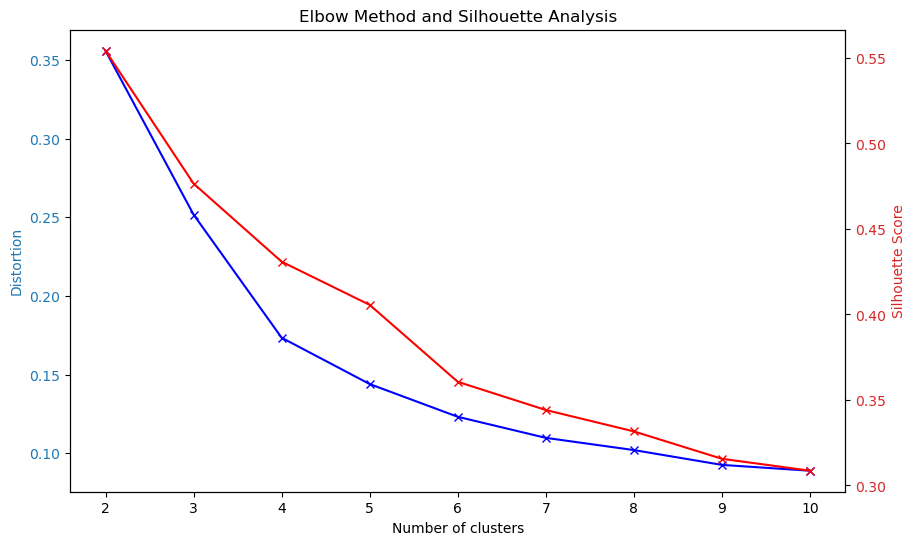

In [7]:
# optimize (using elbow and silhouette) and fit the clusterer
distortions = []
silhouette_scores = []
mapping1 = {}
mapping2 = {}

for i in range(2, 11):
    km_clusterer = KMeans(n_clusters=i, init='k-means++', max_iter=100, random_state=64) 
    km_clusterer.fit(weights_array)
    
    distortions.append(sum(np.min(cdist(weights_array, km_clusterer.cluster_centers_, 'euclidean'), axis=1)**2) / weights_array.shape[0])     
    mapping1[i] = distortions[-1]
    
    score = silhouette_score(weights_array, km_clusterer.labels_, sample_size=10000)
    silhouette_scores.append(score)  
    mapping2[i] = score

# Plotting
fig, ax1 = plt.subplots(figsize=(10, 6))

color = 'tab:blue'
ax1.set_xlabel('Number of clusters')
ax1.set_ylabel('Distortion', color=color)
ax1.plot(list(mapping1.keys()), list(mapping1.values()), 'bx-')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()  
color = 'tab:red'
ax2.set_ylabel('Silhouette Score', color=color)
ax2.plot(list(mapping2.keys()), list(mapping2.values()), 'rx-')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Elbow Method and Silhouette Analysis')
plt.show()

In [8]:
# Getting a balanced number of clusters

# 1. Normailize both metrics to 0-1 scale so they are comparable
d_vals = np.array(list(mapping1.values()))
s_vals = np.array(list(mapping2.values()))

# Invert Distortion (since we want to minimize it, but maximize score)
d_norm = 1 - (d_vals - d_vals.min()) / (d_vals.max() - d_vals.min())
s_norm = (s_vals - s_vals.min()) / (s_vals.max() - s_vals.min())

# 2. Combined Score (Harmonic Mean or Simple Average)
# We want maximizing both (high silhouette, low distortion -> high inverted distortion)
combined_score = (d_norm + s_norm) / 2

# 3. Best K
optimum_k_index = np.argmax(combined_score)
optimum_k = list(mapping1.keys())[optimum_k_index]
print(f"Suggested Optimum k: {optimum_k}")

Suggested Optimum k: 5


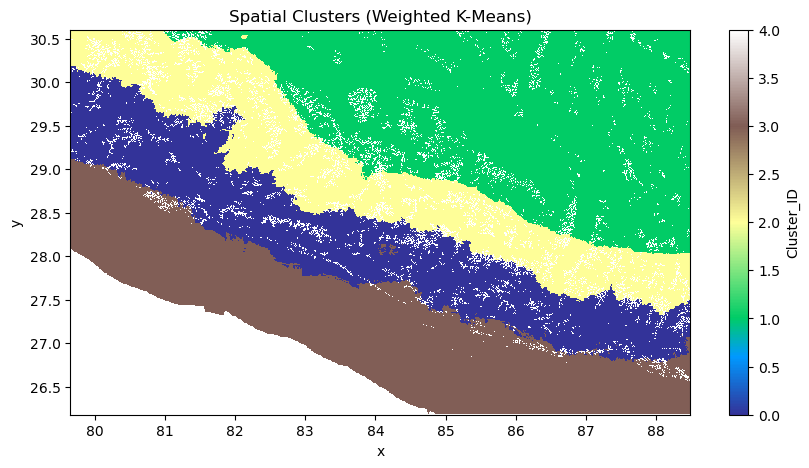

In [9]:
# Final Fitting with k=4

km_clusterer = KMeans(n_clusters=5, init='k-means++', max_iter=100, random_state=64) 
km_clusterer.fit(weights_array)
cluster_labels = km_clusterer.labels_  

rows, cols = spatial_coords['shape']
cluster_flat = np.full(rows * cols, np.nan)
cluster_flat[valid_mask.flatten()] = cluster_labels 
cluster_grid = cluster_flat.reshape(rows, cols)

cluster_rxr = xr.DataArray(
    cluster_grid,
    coords={"y": spatial_coords['y'], "x": spatial_coords['x']},
    dims=("y", "x"),
    name="Cluster_ID"
)

cluster_rxr.rio.write_crs(spatial_coords['crs'], inplace=True)

plt.figure(figsize=(10, 5))
cluster_rxr.plot(cmap='terrain')
plt.title('Spatial Clusters (Weighted K-Means)')
plt.show()

In [10]:
from scipy.ndimage import generic_filter, distance_transform_edt
from scipy.stats import mode

# 1. Fill NaNs (Nearest Neighbor)
indices = distance_transform_edt(np.isnan(cluster_grid), return_distances=False, return_indices=True)
cluster_filled = cluster_grid[tuple(indices)]

# 2. Despeckle (Majority Filter)
# Define mode function for generic_filter (returns the most frequent value in the window)
def majority_mode(x):
    return mode(x, axis=None, keepdims=False)[0]

# Apply 3x3 modal filter to smooth out isolated "salt and pepper" pixels
cluster_refined = generic_filter(cluster_filled, majority_mode, size=3)

# 3. Export to rioxarray
refined_da = xr.DataArray(
    cluster_refined,
    coords={"y": spatial_coords['y'], "x": spatial_coords['x']},
    dims=("y", "x"),
    name="Cluster_ID_Refined"
)
refined_da.rio.write_crs(spatial_coords['crs'], inplace=True)

<xarray.DataArray 'Cluster_ID_Refined' (y: 493, x: 983)> Size: 4MB
array([[2., 2., 2., ..., 1., 1., 1.],
       [2., 2., 2., ..., 1., 1., 1.],
       [2., 2., 2., ..., 1., 1., 1.],
       ...,
       [4., 4., 4., ..., 3., 3., 3.],
       [4., 4., 4., ..., 3., 3., 3.],
       [4., 4., 4., ..., 3., 3., 3.]], shape=(493, 983))
Coordinates:
  * y            (y) float64 4kB 30.6 30.59 30.58 30.57 ... 26.2 26.19 26.18
  * x            (x) float64 8kB 79.66 79.67 79.68 79.69 ... 88.46 88.47 88.48
    spatial_ref  int64 8B 0

In [11]:
# Rename and regroup clusters: 4 & 3 -> 0, 0 -> 1, 1 & 2 -> 2

conditions = [
    np.isin(refined_da.values, [3, 4]),
    refined_da.values == 0,
    np.isin(refined_da.values, [1, 2])
]
choices = [0, 1, 2]

# np.select evaluates conditions simultaneously into a new array (avoids overlap)
regrouped_da = refined_da.copy(
    data=np.select(conditions, choices, default=np.nan)
)

# Export the regrouped raster
regrouped_da.rio.to_raster(r"E:\ClimateData_Precipitation\Data\Processed\Spatial_clustering\Precipitation_clusters.tif")


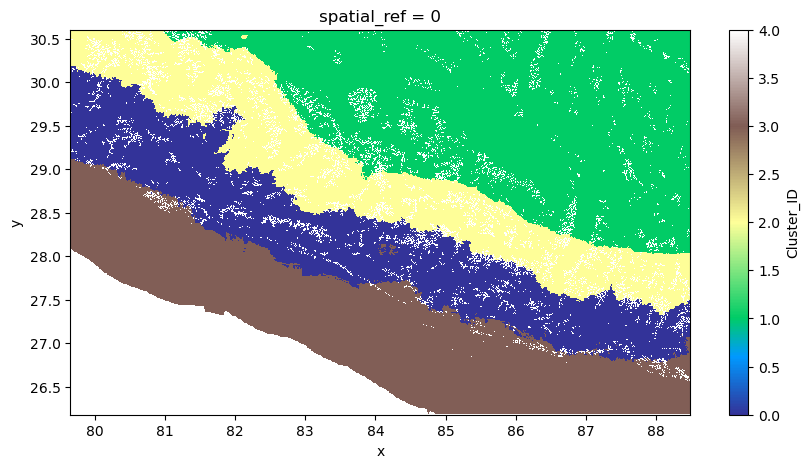

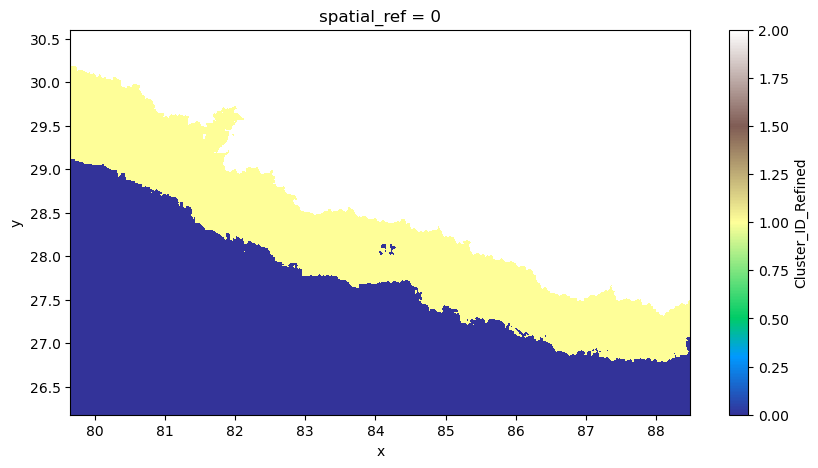

In [13]:
plt.figure(figsize=(10, 5))
cluster_rxr.plot(cmap='terrain')
plt.show()

# Visualize Comparison
plt.figure(figsize=(10, 5))
regrouped_da.plot(cmap='terrain')

plt.show()